# GlacierGuard AI — Final Reproducible Satellite Analysis
**Nepal / Langtang region | Sentinel-2 Level-2A | 12 August 2026 and 13 October 2026**

**Scope:** This notebook uses the aligned, exported Sentinel-2 data in `glacierguard_data.npz`. It reproduces index-threshold maps and statistics, performs basic quality checks, and trains an **unsupervised K-Means clustering model** as a machine-learning demonstration. It does **not** verify lake disappearance, flood damage, glacier retreat, or supervised classification accuracy.

**Reproducibility:** Put `glacierguard_data.npz` beside this notebook and run all cells. `preprocess_raw_satellite.py` is provided separately for processing original Copernicus Browser TIFF ZIPs. The existing `GlacierGuard_AI (1).ipynb` remains the record of the original Colab preprocessing steps.

**Dataset provenance:** Copernicus Browser Sentinel-2 L2A exports; four reflectance bands B03, B04, B08 and B11. The geographic study area is defined by the **October image footprint**, approximately longitude 85.634737–85.727949° E and latitude 28.293423–28.348579° N, in the broader Langtang region of Nepal. This is a geographic study window, not a verified lake or flood location.

**Quality caveats:** No Sentinel-2 SCL cloud/shadow mask, no independent water/snow ground truth, no field validation, two different seasonal dates. The B11 export was on the approximately 10 m output grid; its native Sentinel-2 resolution is 20 m. Index thresholds are exploratory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import joblib
import json

OUT=Path('results'); OUT.mkdir(exist_ok=True)
source=Path('glacierguard_data.npz')
if not source.exists():
    raise FileNotFoundError('Place glacierguard_data.npz next to this notebook.')
with np.load(source) as data:
    arrays={k:data[k] for k in data.files}
valid=arrays['valid_mask'].astype(bool)
shape=valid.shape
pixel_area_m2=9.997848231820688 * 10.001336758735492 
pixel_area_km2=pixel_area_m2/1e6
print('Data loaded:', len(arrays),'arrays | shape:',shape)
print('Shared valid pixels:',int(valid.sum()))
print('Reference coverage:',f'{valid.mean()*100:.2f}%')
print('Shared valid area:',f'{valid.sum()*pixel_area_km2:.3f} km²')

Data loaded: 15 arrays | shape: (1202, 1829)
Shared valid pixels: 558610
Reference coverage: 25.41%
Shared valid area: 55.856 km²


## 1. Coverage and geographic alignment check
The August B03 reference image was exported in **EPSG:32645** at about 10 m/pixel; the October image was exported in **EPSG:4326**. October bands were reprojected to the August grid before indices were calculated. Shared valid coverage is a **footprint statistic**, not a positional-accuracy metric. Matching visible mountain features is only a preliminary visual check; independent registration control points have not been measured.

In [2]:
print('August reference image:', '1829 × 1202 pixels; EPSG:32645')
print('October source image:', '1036 × 613 pixels; EPSG:4326')
print('Common valid pixels:',int(valid.sum()),'of',valid.size)
print('Coverage of August reference:',f'{100*valid.mean():.2f}%')
print('October source bounds: lon 85.634737–85.727949, lat 28.293423–28.348579')
print('Approximate centre: 28.321001° N, 85.681343° E')

August reference image: 1829 × 1202 pixels; EPSG:32645
October source image: 1036 × 613 pixels; EPSG:4326
Common valid pixels: 558610 of 2198458
Coverage of August reference: 25.41%
October source bounds: lon 85.634737–85.727949, lat 28.293423–28.348579
Approximate centre: 28.321001° N, 85.681343° E


## 2. Image previews (B04/B03/B08 false-colour)
B02 (blue) was not downloaded, so these are **not natural-colour RGB**. Both dates use the same per-band display scaling to support comparison. Bright areas can represent snow or clouds; appearance alone does not separate them.

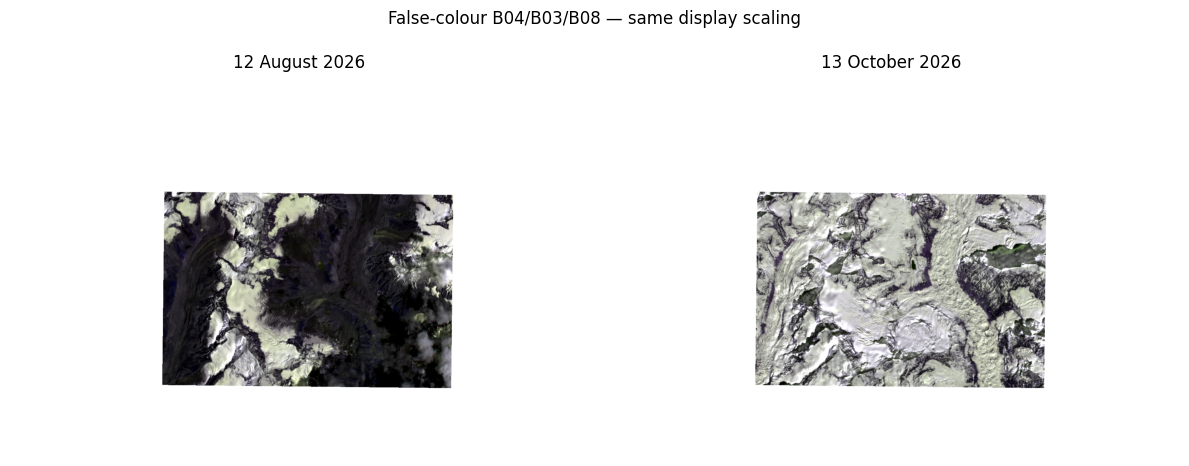

In [3]:
def common_false_colour(prefix):
    return np.stack([arrays[f'{prefix}_B04'],arrays[f'{prefix}_B03'],arrays[f'{prefix}_B08']],axis=-1).astype('float32')
a=common_false_colour('before'); b=common_false_colour('after')
lo=np.array([np.percentile(np.r_[a[:,:,i][valid],b[:,:,i][valid]],2) for i in range(3)])
hi=np.array([np.percentile(np.r_[a[:,:,i][valid],b[:,:,i][valid]],98) for i in range(3)])
def stretch(x):
    y=np.clip((x-lo)/(hi-lo),0,1); y[~valid]=1; return y
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,x,t in zip(axes,[a,b],['12 August 2026','13 October 2026']):
    ax.imshow(stretch(x)); ax.set_title(t);ax.axis('off')
fig.suptitle('False-colour B04/B03/B08 — same display scaling')
fig.tight_layout(); fig.savefig(OUT/'false_colour_comparison.png',dpi=150,bbox_inches='tight');plt.show()

## 3. NDWI and NDSI maps
NDWI = (B03 − B08)/(B03 + B08); NDSI = (B03 − B11)/(B03 + B11). These are spectral indices, not ML predictions. Pixel values are restricted to the shared valid grid.

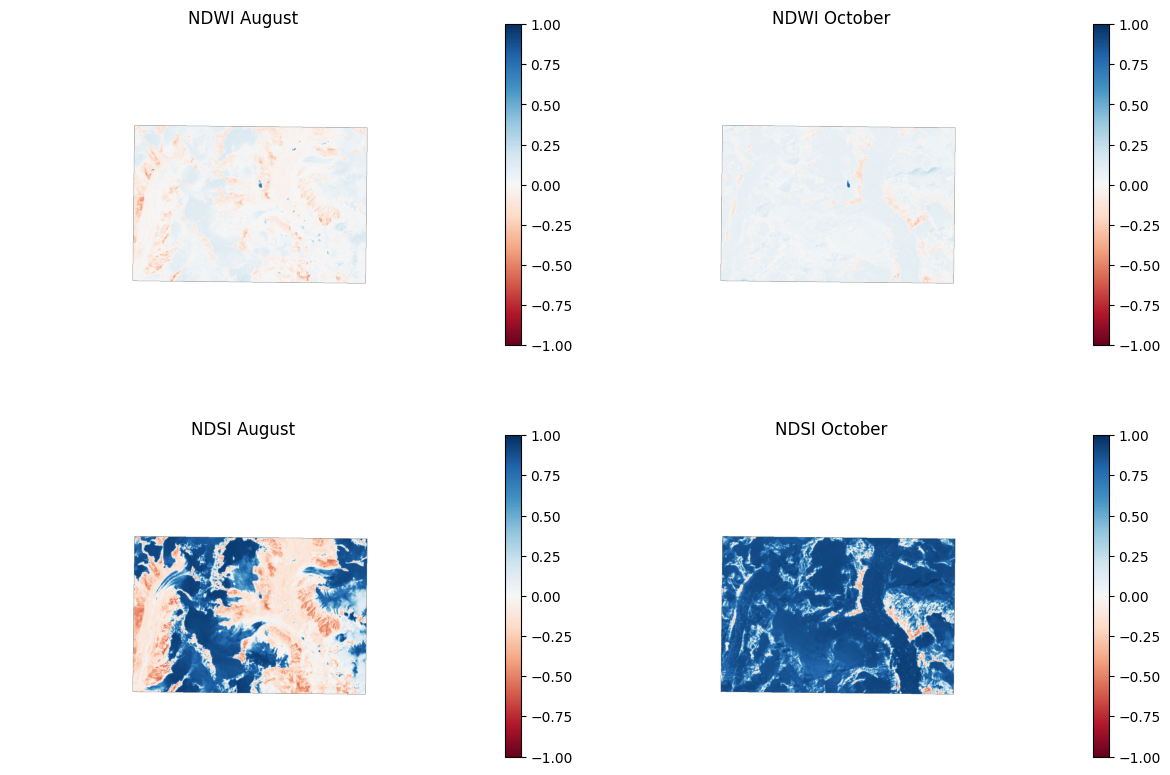

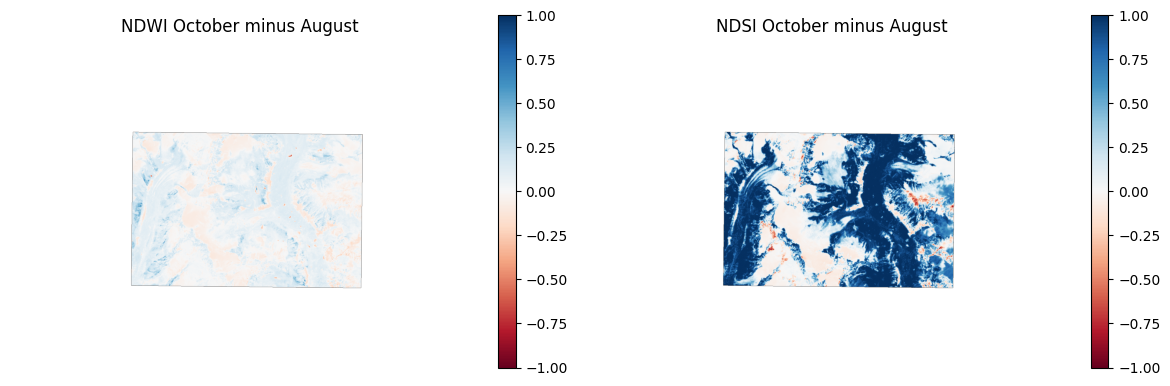

Mean NDWI difference: 0.0478
Mean NDSI difference: 0.4938


In [4]:
fig,axes=plt.subplots(2,2,figsize=(12,9))
for ax,key,title in zip(axes.flat,['ndwi_before','ndwi_after','ndsi_before','ndsi_after'],['NDWI August','NDWI October','NDSI August','NDSI October']):
    img=ax.imshow(np.where(valid,arrays[key],np.nan),cmap='RdBu',vmin=-1,vmax=1)
    ax.set_title(title);ax.axis('off');fig.colorbar(img,ax=ax,shrink=.7)
fig.tight_layout();fig.savefig(OUT/'index_maps.png',dpi=140,bbox_inches='tight');plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,key,title in zip(axes,['ndwi_change','ndsi_change'],['NDWI October minus August','NDSI October minus August']):
    img=ax.imshow(np.where(valid,arrays[key],np.nan),cmap='RdBu',vmin=-1,vmax=1)
    ax.set_title(title);ax.axis('off');fig.colorbar(img,ax=ax,shrink=.75)
fig.tight_layout();fig.savefig(OUT/'index_changes.png',dpi=140,bbox_inches='tight');plt.show()
print('Mean NDWI difference:',round(float(np.nanmean(arrays['ndwi_change'])),4))
print('Mean NDSI difference:',round(float(np.nanmean(arrays['ndsi_change'])),4))

## 4. Preliminary threshold-based candidates and snow overlap
Candidate water: NDWI > 0.3. Candidate snow/ice: NDSI > 0.4. **The water and snow thresholds overlap considerably**, making unfiltered water area estimates unreliable. Refined water candidates exclude NDSI snow candidates, but even those are **not validated water detections**.

                           Metric  Pixels Area_km2
           Shared valid footprint  558610  55.8564
      Raw candidate water, August     647   0.0647
     Raw candidate water, October     234   0.0234
 Raw water & snow overlap, August     380   0.0380
Raw water & snow overlap, October     234   0.0234
  Refined candidate water, August     267   0.0267
 Refined candidate water, October       0   0.0000
       Candidate snow/ice, August  219035  21.9017
      Candidate snow/ice, October  499070  49.9029
          Raw candidate new water      25   0.0025
         Raw candidate lost water     438   0.0438
           Candidate new snow/ice  284360  28.4337
          Candidate lost snow/ice    4325   0.4325


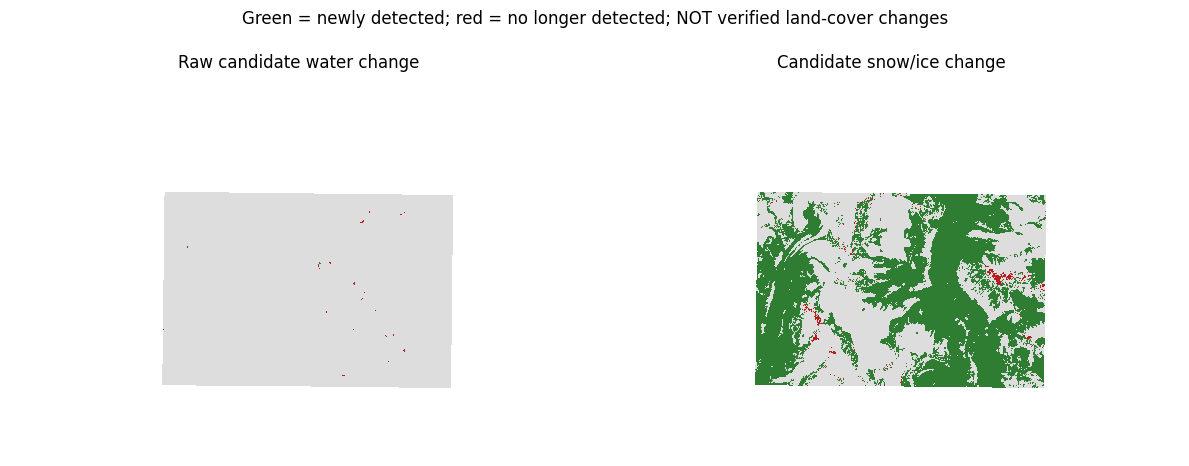

In [5]:
w0=(arrays['ndwi_before']>0.3)&valid; w1=(arrays['ndwi_after']>0.3)&valid
s0=(arrays['ndsi_before']>0.4)&valid; s1=(arrays['ndsi_after']>0.4)&valid
wc0=w0&~s0;wc1=w1&~s1
neww=w1&~w0;lostw=w0&~w1
news=s1&~s0;losts=s0&~s1
metrics=[
 ('Shared valid footprint',valid.sum()),('Raw candidate water, August',w0.sum()),
 ('Raw candidate water, October',w1.sum()),('Raw water & snow overlap, August',(w0&s0).sum()),
 ('Raw water & snow overlap, October',(w1&s1).sum()),
 ('Refined candidate water, August',wc0.sum()),('Refined candidate water, October',wc1.sum()),
 ('Candidate snow/ice, August',s0.sum()),('Candidate snow/ice, October',s1.sum()),
 ('Raw candidate new water',neww.sum()),('Raw candidate lost water',lostw.sum()),
 ('Candidate new snow/ice',news.sum()),('Candidate lost snow/ice',losts.sum()),
]
stats=pd.DataFrame([{'Metric':name,'Pixels':int(count),'Area_km2':float(count*pixel_area_km2)} for name,count in metrics])
stats.to_csv(OUT/'validated_preliminary_statistics.csv',index=False)
print(stats.to_string(index=False,formatters={'Area_km2':'{:.4f}'.format}))
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,added,removed,title in [(axes[0],neww,lostw,'Raw candidate water change'),(axes[1],news,losts,'Candidate snow/ice change')]:
    m=np.zeros(shape,dtype=np.uint8);m[added]=1;m[removed]=2
    ax.imshow(np.ma.masked_where(~valid,m),cmap=ListedColormap(['#dddddd','#2e7d32','#b71c1c']),vmin=0,vmax=2,interpolation='nearest')
    ax.set_title(title);ax.axis('off')
fig.suptitle('Green = newly detected; red = no longer detected; NOT verified land-cover changes')
fig.tight_layout();fig.savefig(OUT/'candidate_change_map.png',dpi=150,bbox_inches='tight');plt.show()

## 5. Actual machine-learning demonstration: unsupervised K-Means
A **MiniBatchKMeans** model is trained on pooled, randomly sampled valid pixels from both dates. Features: B03, B04, B08, B11, NDWI, NDSI. The model discovers **four numerical spectral clusters**; clusters are **not labelled water, snow, cloud, or ice**. A held-out silhouette score is an **internal clustering measure, not classification accuracy**. We do not report precision, recall, F1 or supervised accuracy because there are no independent ground-truth labels.

Model: MiniBatchKMeans (unsupervised)
Training pixels: 40000  | spectral clusters: 4
Held-out silhouette (NOT accuracy): 0.41


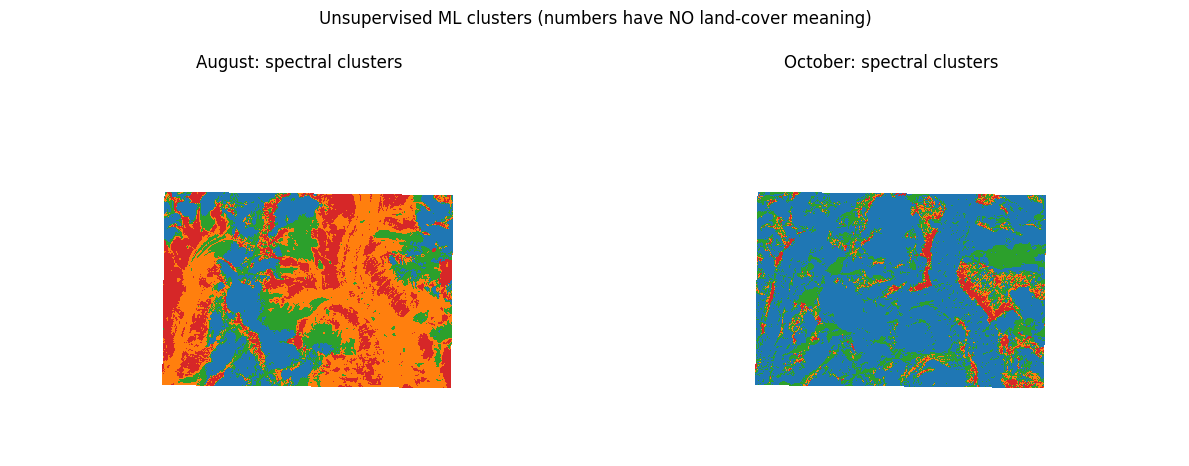

 Cluster  August_pixels  October_pixels
       0         115264          373879
       1         210143           29239
       2         106241          129179
       3         126962           26313
Fraction of shared pixels changing numerical cluster: 70.69 % (not validated land-cover change)


In [6]:
FEATURES=['B03','B04','B08','B11','ndwi','ndsi']
def features(prefix):
    x=np.column_stack([arrays[f'{f}_{prefix}' if f in ('ndwi','ndsi') else f'{prefix}_{f}'][valid] for f in FEATURES]).astype('float32')
    if not np.isfinite(x).all():raise ValueError('Nonfinite values in feature matrix')
    return x
X0=features('before');X1=features('after')
rng=np.random.default_rng(42)
ix0=rng.choice(len(X0),size=min(20000,len(X0)),replace=False)
ix1=rng.choice(len(X1),size=min(20000,len(X1)),replace=False)
Xtrain=np.concatenate([X0[ix0],X1[ix1]])
scaler=StandardScaler().fit(Xtrain)
model=MiniBatchKMeans(n_clusters=4,random_state=42,batch_size=2048,n_init=5,max_iter=150)
model.fit(scaler.transform(Xtrain))

ix0test=rng.choice(np.setdiff1d(np.arange(len(X0)),ix0),size=600,replace=False)
ix1test=rng.choice(np.setdiff1d(np.arange(len(X1)),ix1),size=600,replace=False)
Xtest=np.concatenate([X0[ix0test],X1[ix1test]])
Ztest=scaler.transform(Xtest)
testlabels=model.predict(Ztest)
sil=float(silhouette_score(Ztest,testlabels)) if len(np.unique(testlabels))>1 else float('nan')
print('Model: MiniBatchKMeans (unsupervised)')
print('Training pixels:',len(Xtrain),' | spectral clusters:',model.n_clusters)
print('Held-out silhouette (NOT accuracy):',round(sil,3))
joblib.dump({'model':model,'scaler':scaler,'features':FEATURES,'note':'Unsupervised spectral clusters; no semantic labels or classification accuracy'},OUT/'glacierguard_kmeans.joblib')
label0=model.predict(scaler.transform(X0));label1=model.predict(scaler.transform(X1))
clusters=[]
for label in [label0,label1]:
    grid=np.full(shape,np.nan,dtype='float32');grid[valid]=label;clusters.append(grid)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,m,title in zip(axes,clusters,['August: spectral clusters','October: spectral clusters']):
    im=ax.imshow(m,cmap='tab10',vmin=0,vmax=9,interpolation='nearest');ax.set_title(title);ax.axis('off')
fig.suptitle('Unsupervised ML clusters (numbers have NO land-cover meaning)')
fig.tight_layout();fig.savefig(OUT/'unsupervised_clusters.png',dpi=150,bbox_inches='tight');plt.show()
cluster_counts=pd.DataFrame({'Cluster':np.arange(4),'August_pixels':np.bincount(label0,minlength=4),'October_pixels':np.bincount(label1,minlength=4)})
cluster_counts.to_csv(OUT/'cluster_counts.csv',index=False)
print(cluster_counts.to_string(index=False))
print('Fraction of shared pixels changing numerical cluster:',round(float(np.mean(label0!=label1))*100,2),'% (not validated land-cover change)')

## 6. Validation summary and reporting guidance
- **Spatial coverage:** 558,610 pixels, about **25.41%** of the August reference image. The October footprint is geographically smaller; this is not an accuracy percentage.
- **Alignment:** reprojection to EPSG:32645 completed; visual terrain agreement only. No independent tie-point/root-mean-square registration error was measured.
- **Cloud/shadow:** no SCL or QA cloud mask; contamination cannot be quantified from these four bands alone.
- **Spectral confusion:** August 380/647 and October 234/234 of raw candidate-water pixels also satisfy the snow threshold. After excluding snow candidates, 267 August water candidates and 0 October water candidates remain. **Do not call this lake disappearance.**
- **Snow/ice:** high NDSI can reflect snow or clouds; August–October seasonal conditions differ. Changes cannot be called glacier growth/retreat.
- **Machine learning:** K-Means is trained unsupervised and provides only an internal silhouette score, **not** validated water/snow classification accuracy.
- **Flood connection:** no flood event or flood cause is established by this analysis.

**Suggested report wording:** “We developed a preliminary Sentinel-2 spectral-index change-detection pipeline and an exploratory unsupervised clustering baseline for the Langtang region. Due to limited image overlap, absent cloud masks and ground-truth labels, observed differences are candidates requiring independent verification, not confirmed lake or glacier changes.”

In [7]:
metadata={
 'project':'GlacierGuard AI — exploratory satellite analysis',
 'source':'Copernicus Browser Sentinel-2 Level-2A exports (user-provided)',
 'before_date':'2026-08-12','after_date':'2026-10-13',
 'bands':['B03','B04','B08','B11'],
 'reference_crs':'EPSG:32645','after_source_crs':'EPSG:4326',
 'after_bounds_lonlat':[85.63473701477051,28.293422633156673,85.72794914245605,28.34857928179162],
 'overlap_pixels':int(valid.sum()),'overlap_reference_percent':round(float(valid.mean()*100),4),
 'cloud_mask_applied':False,'independent_ground_truth':False,
 'ml_type':'unsupervised MiniBatchKMeans','ml_clusters':4,
 'ml_internal_silhouette':round(sil,4),
 'ml_accuracy':None,'scientific_validation':'preliminary / unvalidated'
}
(OUT/'analysis_metadata.json').write_text(json.dumps(metadata,indent=2))
print('Results written to:',OUT.resolve())
print('Files:')
for p in sorted(OUT.iterdir()):print(' -',p.name)

Results written to: /mnt/data/glacierguard_final_package/results
Files:
 - analysis_metadata.json
 - candidate_change_map.png
 - cluster_counts.csv
 - false_colour_comparison.png
 - glacierguard_kmeans.joblib
 - index_changes.png
 - index_maps.png
 - unsupervised_clusters.png
 - validated_preliminary_statistics.csv
